# RSNA Pneumonia — детектор YOLO26m, пороги цепочки и тест Kaggle

Вторая часть проекта:
1. обучение YOLO26m находить очаги пневмонии (один класс `opacity`);
2. соединение с классификатором: YOLO запускается, только если `P(пневмония) ≥ t2`;
3. совместный подбор порогов `t2` и `conf` по метрике соревнования;
4. итоговая проверка на нашем test и отправка на Kaggle.

| | Результат |
|---|---|
| YOLO на test (больные + 25% фона) | P 0.496 · R 0.580 · mAP50 0.521 · mAP50-95 0.196 |
| Лучшие пороги (подобраны на val) | `prob2 ≥ 0.50`, `conf ≥ 0.25` |
| Метрика соревнования, val | 0.221 |
| Метрика соревнования, наш test | 0.205 |
| Kaggle, закрытый тест | Private **0.121** · Public 0.048 |

> Ноутбук использует `meta.csv` (с колонкой `split`) и `boxes_512.csv` из ноутбука классификатора,
> а также `val_probs.csv` и `test_probs_f1.csv` из `/content/drive/MyDrive/rsna_project_final/classifier/`.

## 0. Установка и подключение Google Drive

In [ ]:
!pip install -q pydicom pylibjpeg pylibjpeg-libjpeg ultralytics timm

In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


## 1. Данные

Архив, `meta.csv` с готовым делением и боксы в масштабе 512.

In [ ]:
import zipfile
from pathlib import Path
import pandas as pd

zip_path = Path("/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip")
extract_dir = Path("/content/extract_dir")
if not (extract_dir / ".done").exists():
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_dir)
    (extract_dir / ".done").touch()
train_image_path = extract_dir / "stage_2_train_images"

project = Path("/content/drive/MyDrive/rsna_project_final")
meta = pd.read_csv(project / "meta.csv")
boxes = pd.read_csv(project / "boxes_512.csv")
print(meta["split"].value_counts())

split
train    16010
val       5337
test      5337
Name: count, dtype: int64


## 2. Препроцессинг

Те же функции, что в ноутбуке классификатора, без изменений - обе модели должны видеть одинаковые снимки.

In [ ]:
import sys
import numpy as np
import cv2
import pydicom

def percentile_clip(data, lower_percentile=0.5, upper_percentile=99.5):
    low_val, high_val = np.percentile(data, [lower_percentile, upper_percentile])
    return np.clip(data, low_val, high_val)

def read_dicom(dicom_path):
    dcm = pydicom.dcmread(dicom_path)
    img = dcm.pixel_array.astype("float32")
    if dcm.PhotometricInterpretation == "MONOCHROME1":
        img = img.max() - img
    img = percentile_clip(img)
    img = (img - np.min(img)) / (np.max(img) - np.min(img) + sys.float_info.epsilon)
    return np.round(img * 255).astype(np.uint8)

def resize_img(img, size=512):
    resized_img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return resized_img, resized_img.shape[0] / img.shape[0]

## 3. Датасет YOLO

В данные YOLO попадают только `train` и `val` (test не трогаем):
- все снимки с пневмонией;
- фон - снимки классов 0 и 1 с пустым `.txt`, 25% от числа больных. Без фона YOLO привыкает, что очаг есть всегда.

In [ ]:
SIZE = 512
SEED = 42

meta = meta[meta["split"] != "test"]                       # test в YOLO не попадает

sick = meta[meta["label"] == 2]                            # все снимки с боксами
background = []
for split in ["train", "val"]:
    n = int(len(sick[sick["split"] == split]) * 0.25)      # фона — 25% от числа больных
    healthy = meta[(meta["label"] != 2) & (meta["split"] == split)]
    background.append(healthy.sample(n, random_state=SEED))

yolo_df = pd.concat([sick] + background)
print(pd.crosstab(yolo_df["split"], yolo_df["label"]))

label    0    1     2
split                
train  397  504  3607
val    125  175  1202


Один проход: PNG 512 и `.txt` в формате YOLO `0 cx cy w h`, центр и размер в долях от 512.

In [ ]:
from tqdm import tqdm

root = Path("/content/dataset")
for split in ["train", "val"]:
    (root / split / "images").mkdir(parents=True, exist_ok=True)
    (root / split / "labels").mkdir(parents=True, exist_ok=True)

for pid, split in tqdm(zip(yolo_df["patientId"], yolo_df["split"]), total=len(yolo_df)):
    # снимок
    img, _ = resize_img(read_dicom(train_image_path / f"{pid}.dcm"), SIZE)
    cv2.imwrite(str(root / split / "images" / f"{pid}.png"), img)

    # разметка: центр и размер в долях от 512; у фона файл пустой
    lines = []
    for b in boxes[boxes["patientId"] == pid].itertuples():
        cx = (b.x + b.width / 2) / SIZE
        cy = (b.y + b.height / 2) / SIZE
        lines.append(f"0 {cx:.6f} {cy:.6f} {b.width / SIZE:.6f} {b.height / SIZE:.6f}")
    (root / split / "labels" / f"{pid}.txt").write_text("\n".join(lines))

(root / "data.yaml").write_text("path: /content/dataset\ntrain: train/images\nval: val/images\nnc: 1\nnames: ['opacity']\n")

100%|██████████| 6010/6010 [03:43<00:00, 26.91it/s]


84

In [ ]:
for split in ["train", "val"]:
    n_img = len(list((root / split / "images").glob("*.png")))
    n_txt = len(list((root / split / "labels").glob("*.txt")))
    print(split, n_img, "png |", n_txt, "txt")

train 4508 png | 4508 txt
val 1502 png | 1502 txt


## 4. Обучение YOLO26m

Цветовые аугментации (`hsv_*`) выключены. На сером рентгене они бессмысленны. Масштабирование уменьшено до 0.2.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26m.pt")
results = model.train(
    data="/content/dataset/data.yaml",
    imgsz=512,
    epochs=50,
    patience=10,
    batch=64,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    fliplr=0.5,
    scale=0.2,
    cache="ram",
    seed=42,
    project=str(project / "yolo"),
    name="split_v1",
)
print(results.save_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fracti

### Кривые обучения, PR-кривая, матрица ошибок

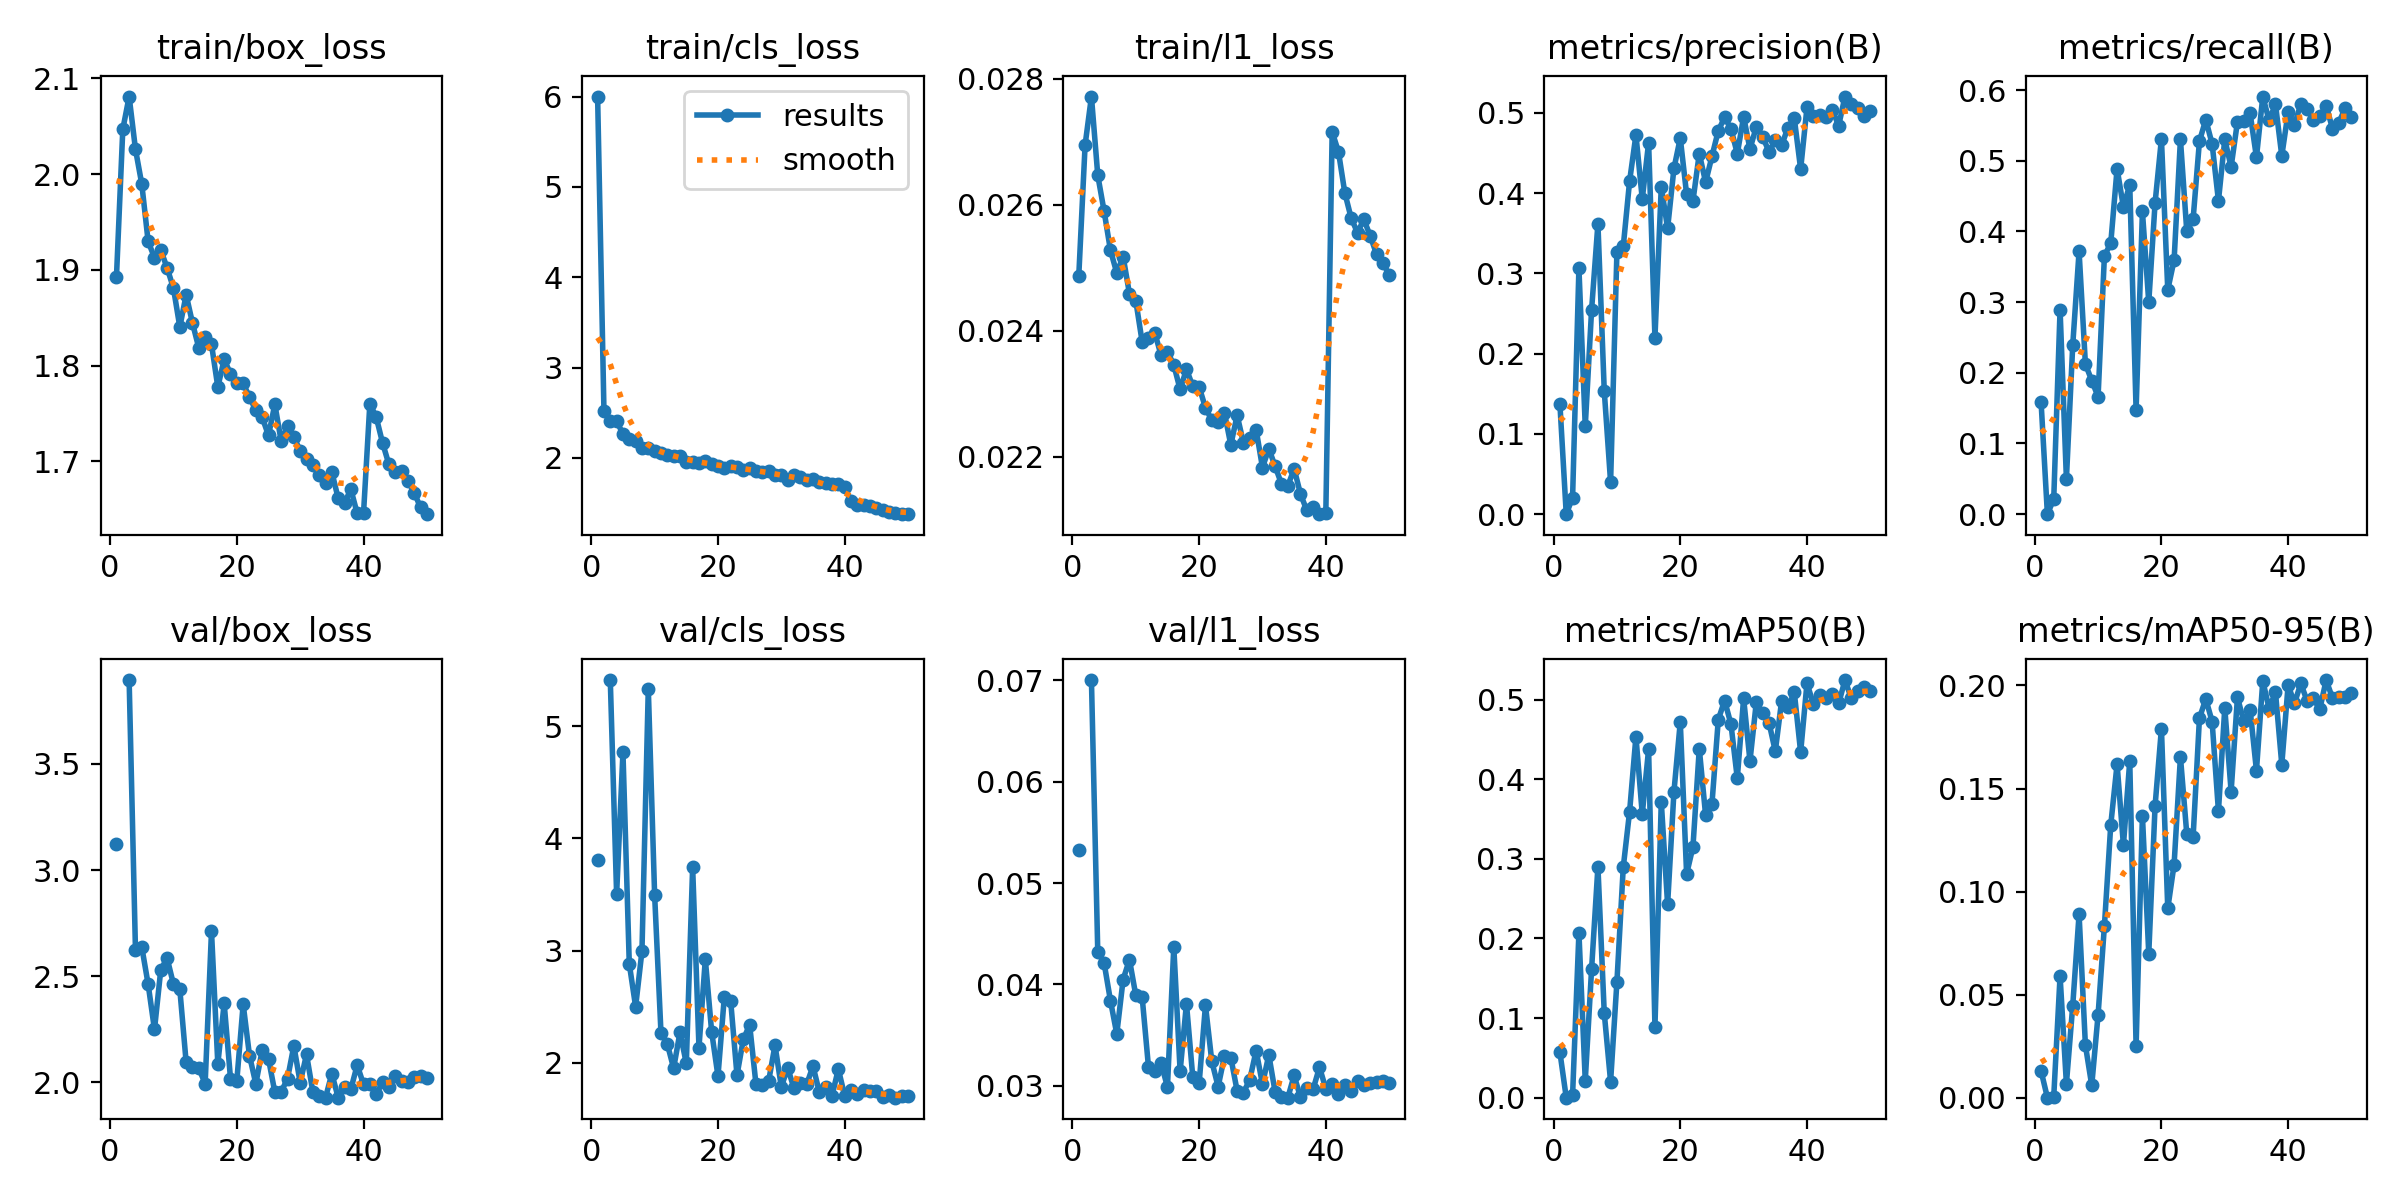

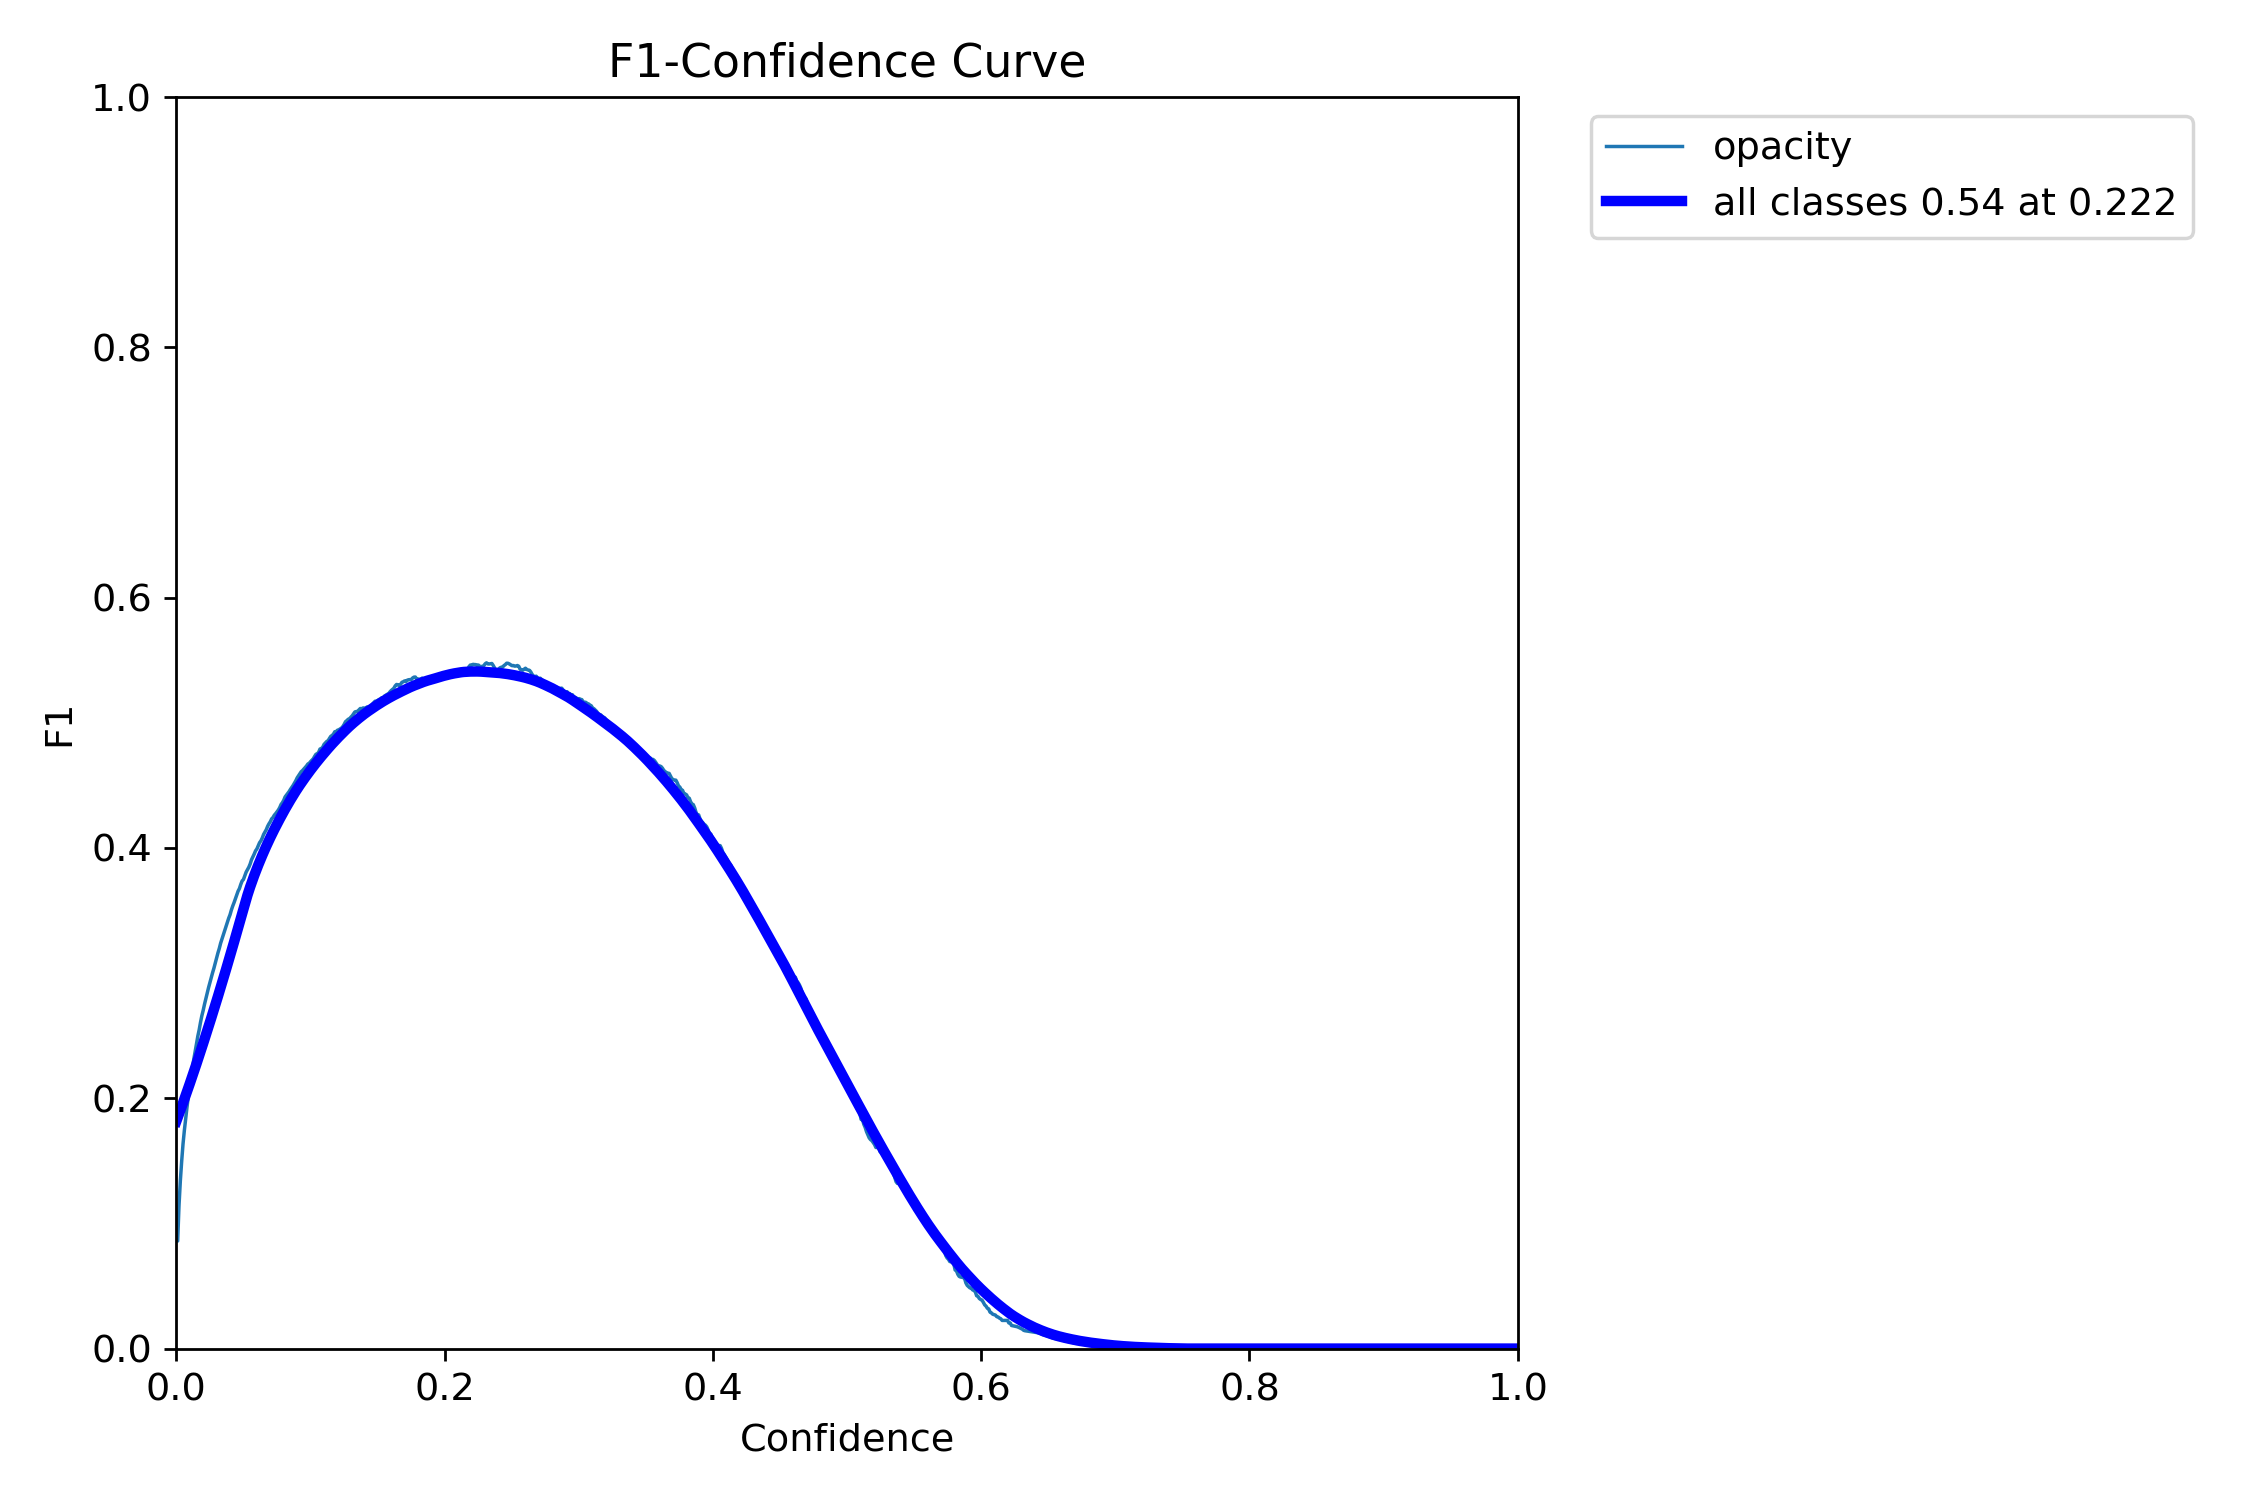

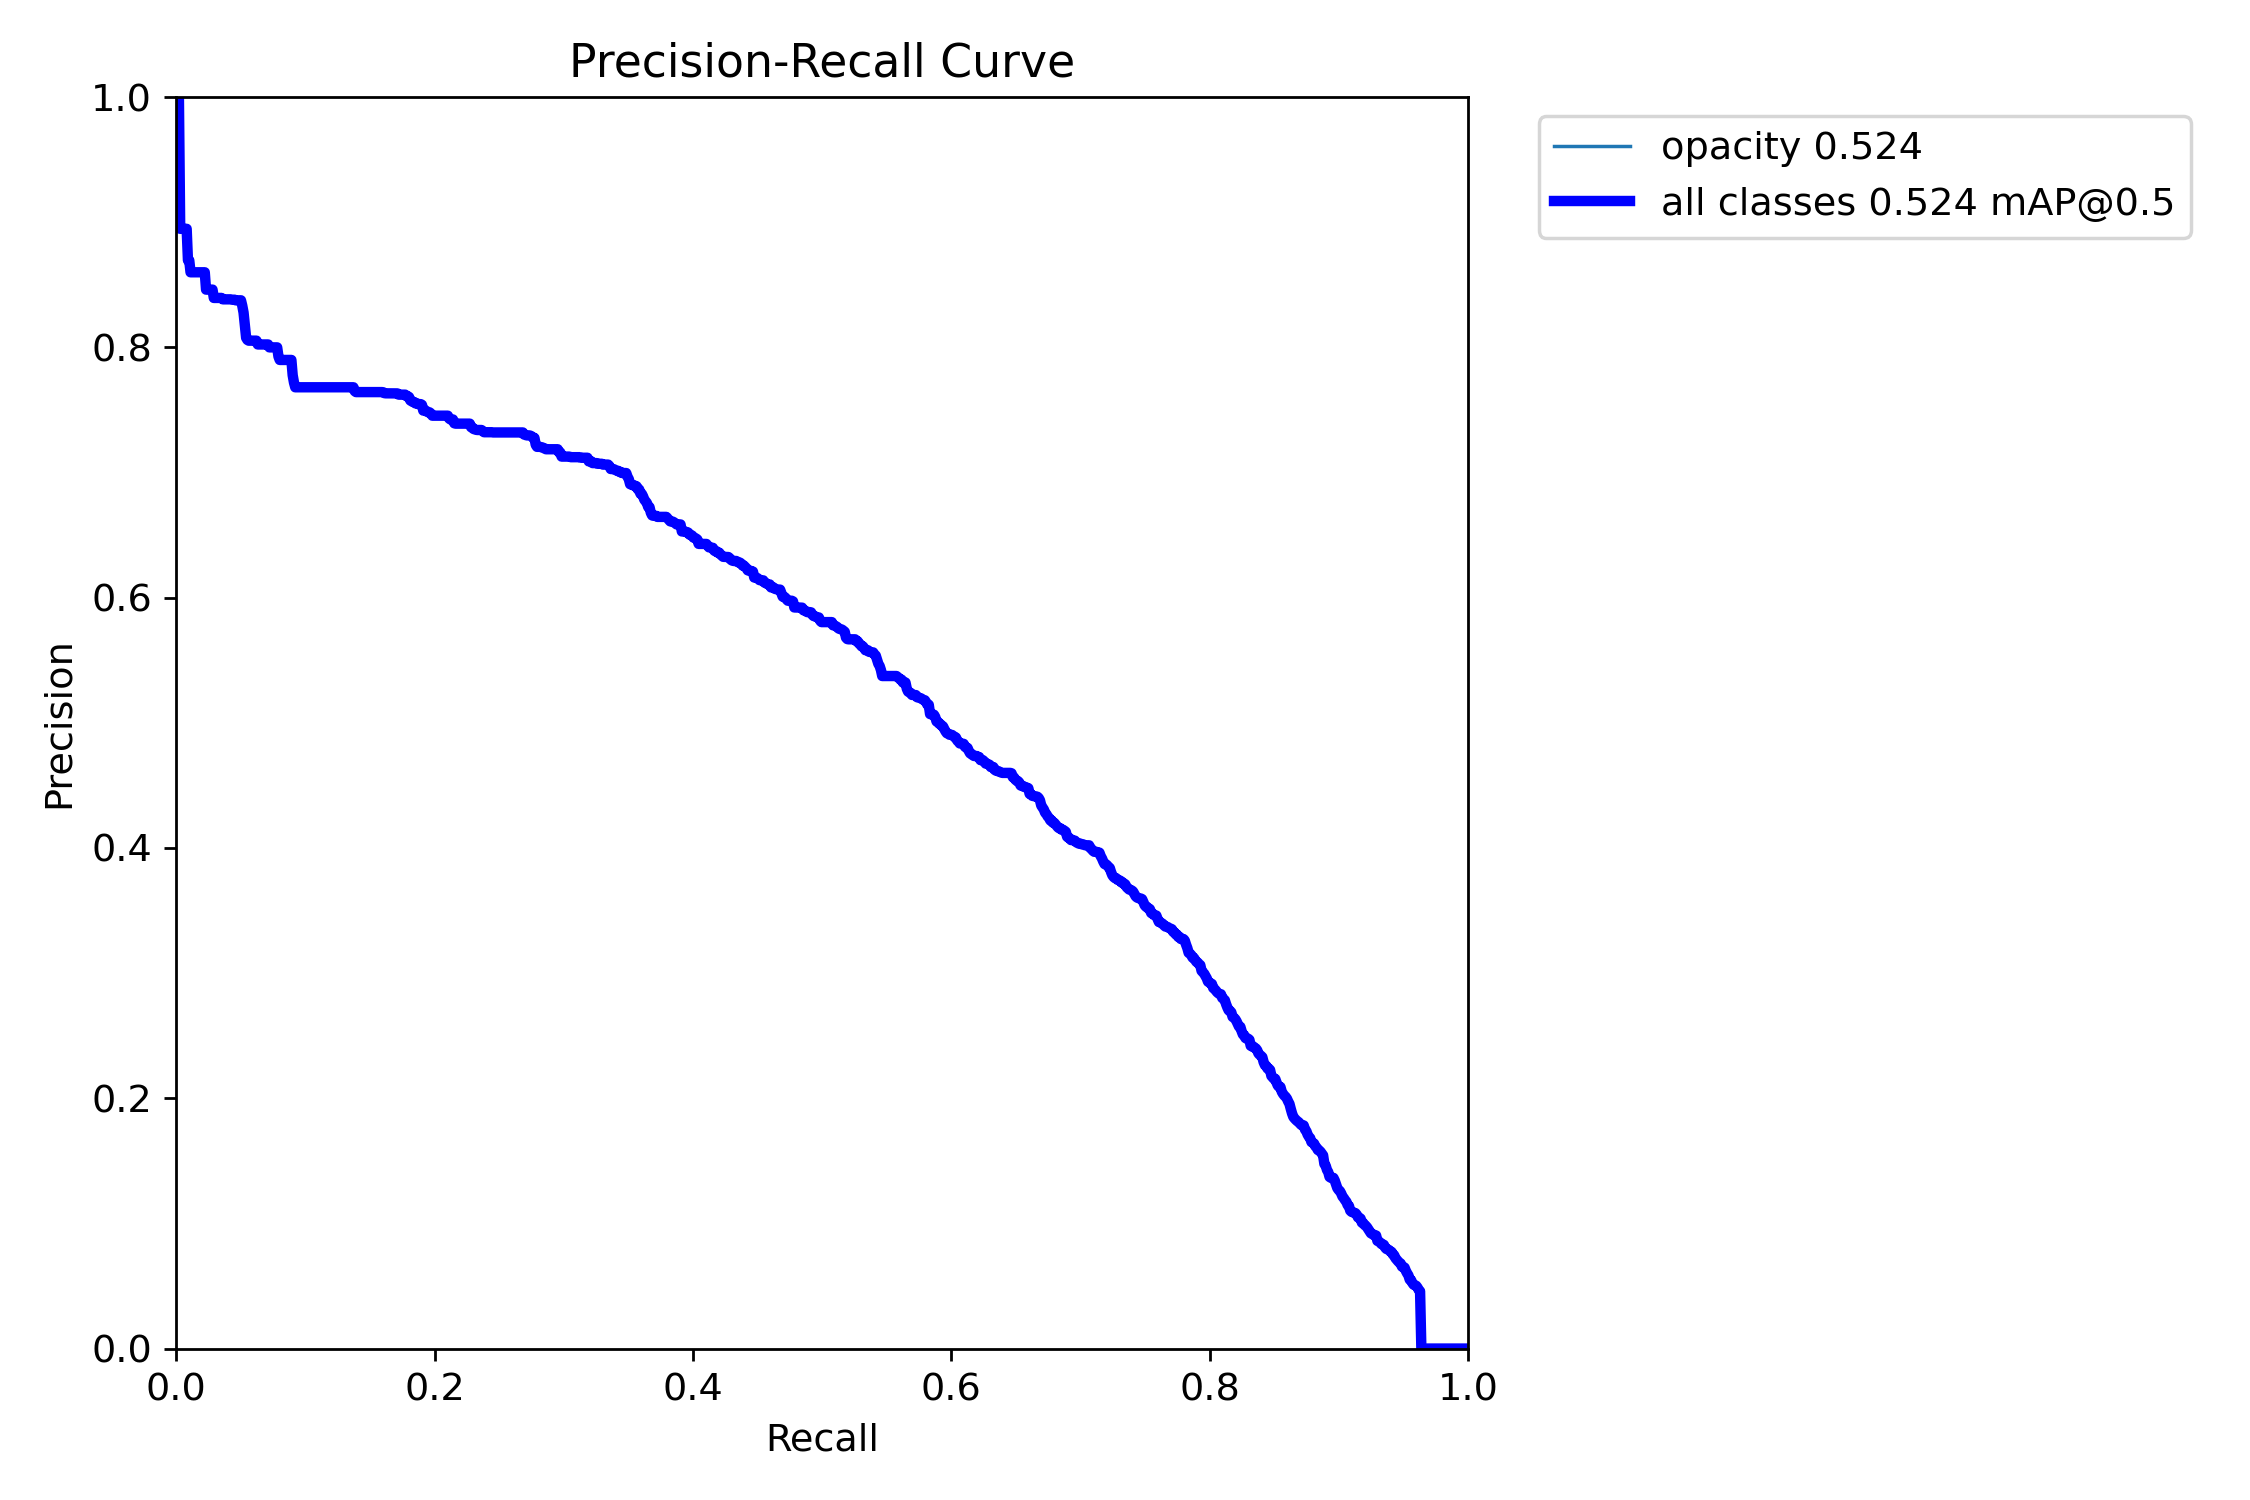

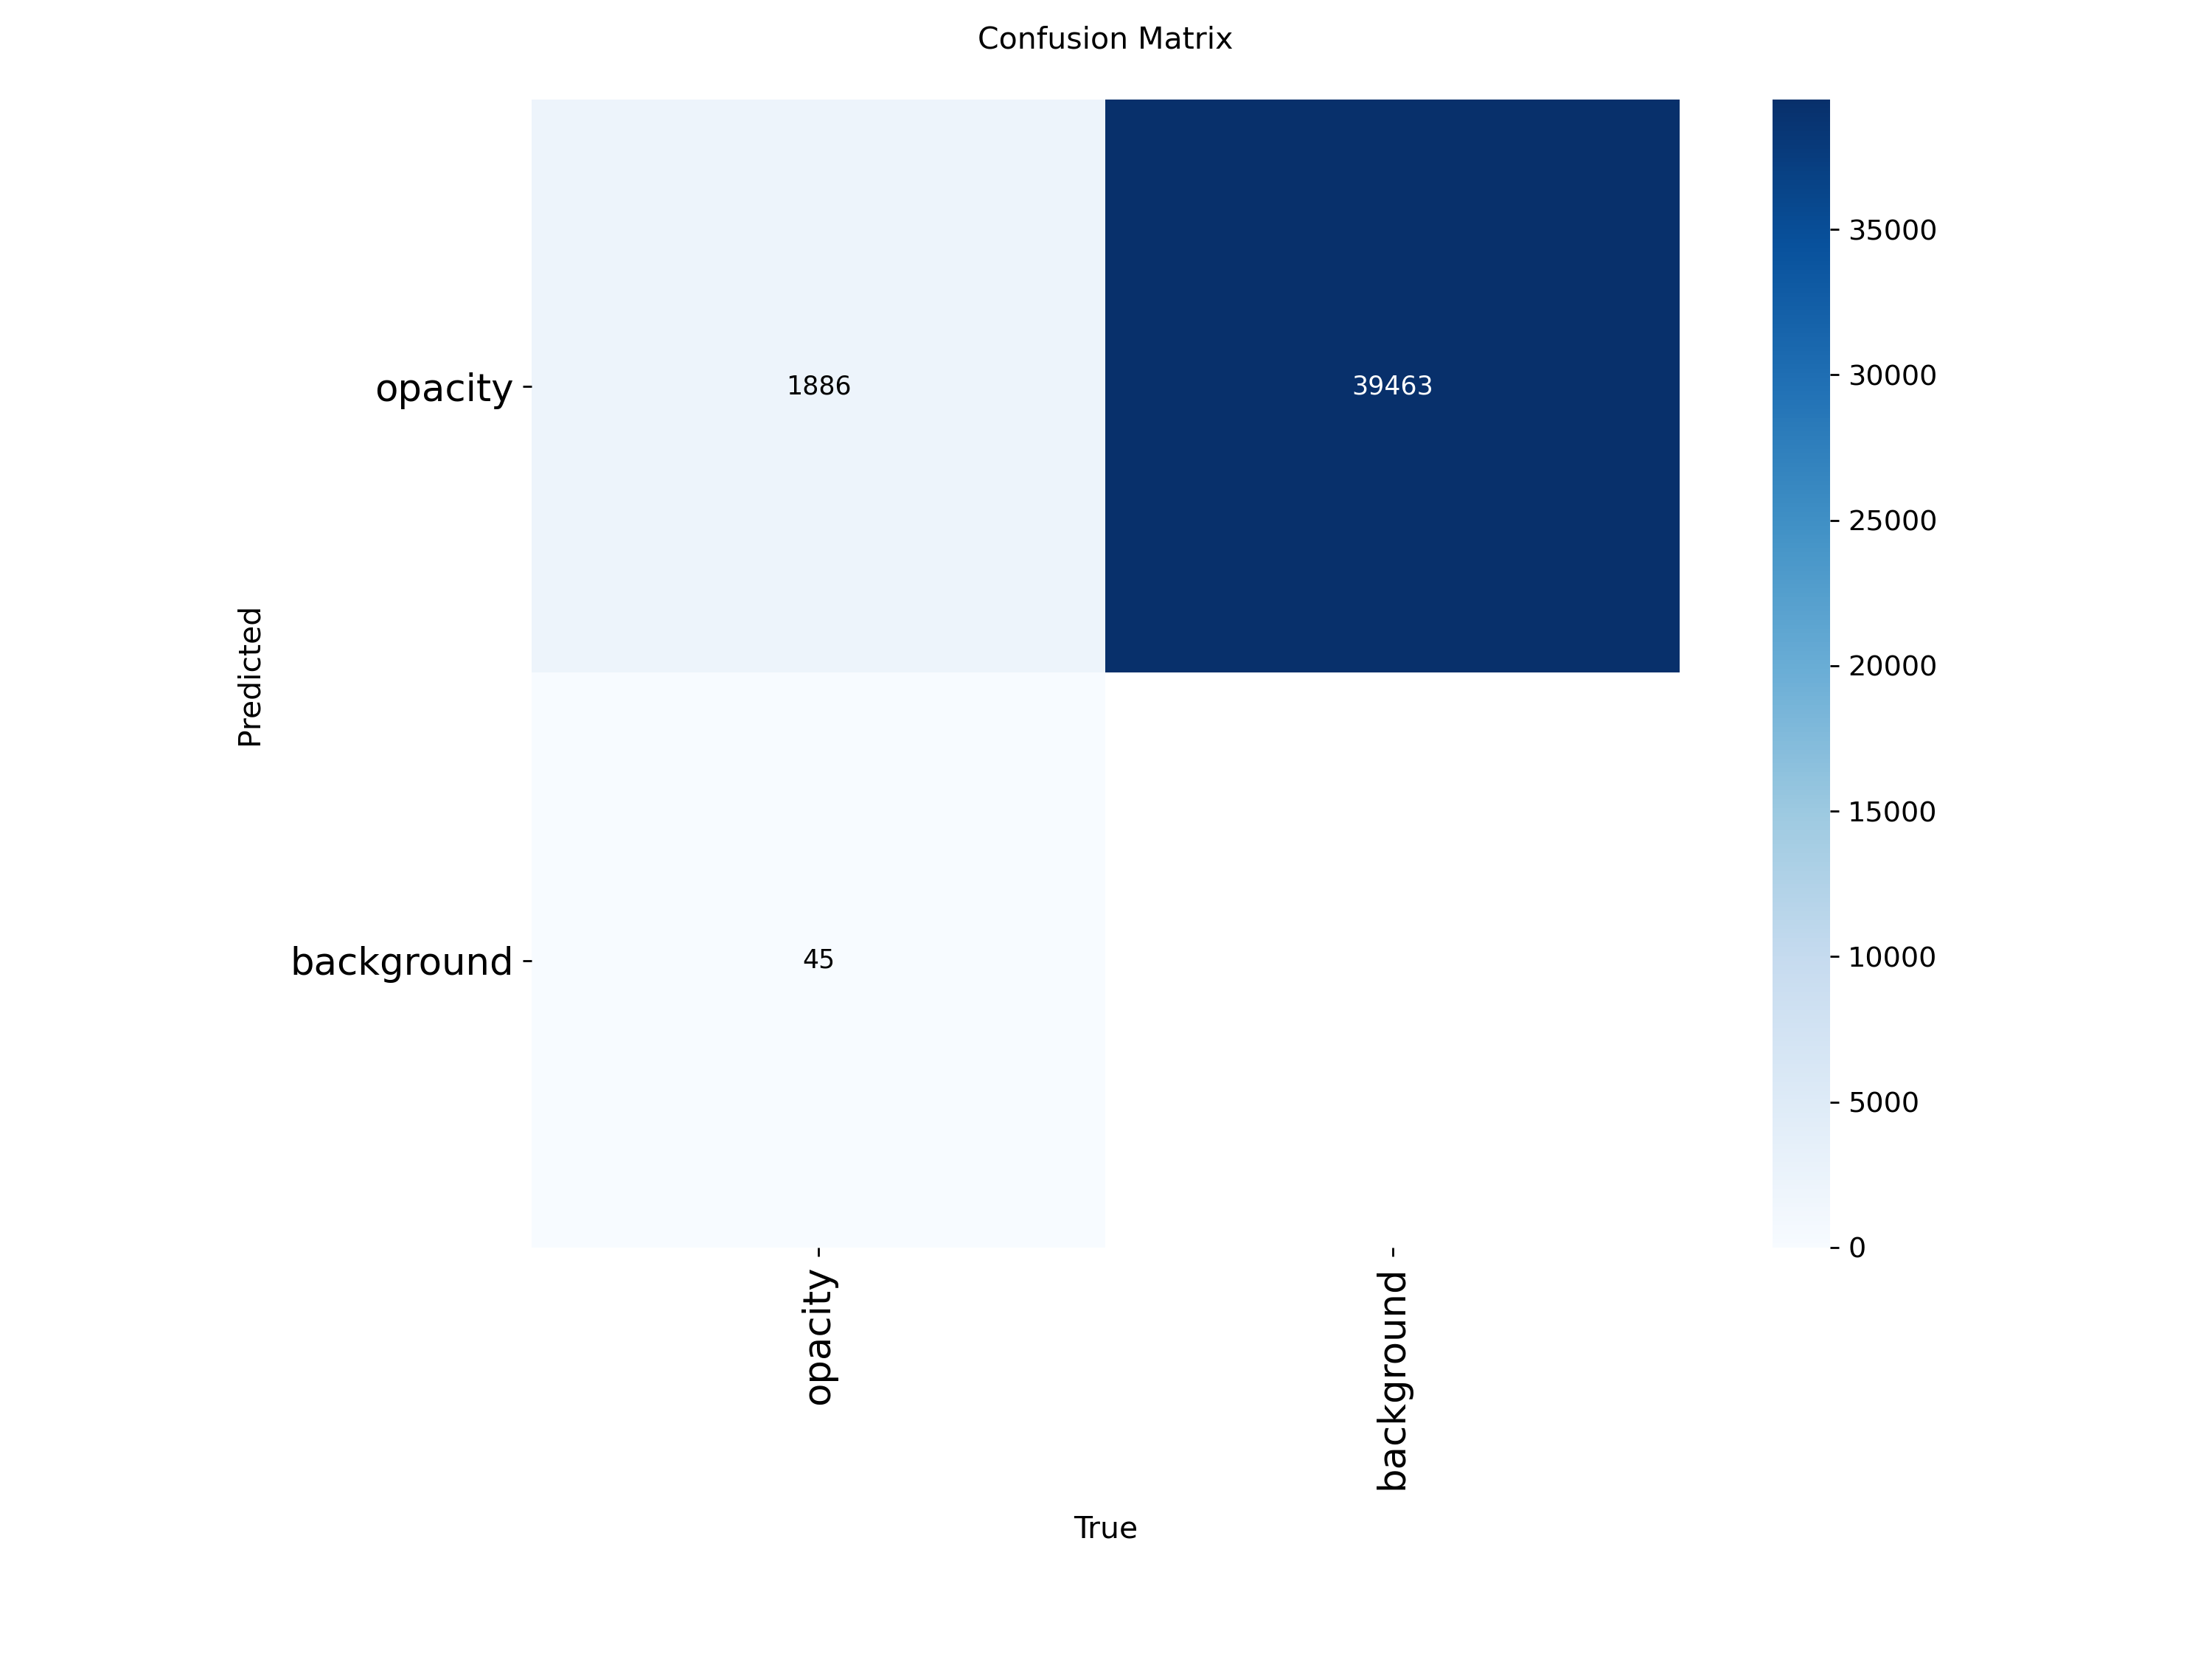

['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'results.png']


In [ ]:
from IPython.display import Image, display
from pathlib import Path
run = Path(results.save_dir)

for name in ["results.png", "BoxF1_curve.png", "BoxPR_curve.png", "confusion_matrix.png"]:
    p = run / name
    if p.exists():
        display(Image(filename=str(p), width=900))
    else:
        print("нет файла:", name)

print(sorted(f.name for f in run.glob("*.png")))   # что ещё есть в папке

### Предсказания глазами
Зелёные рамки - разметка, красные - предсказания YOLO с уверенностью.

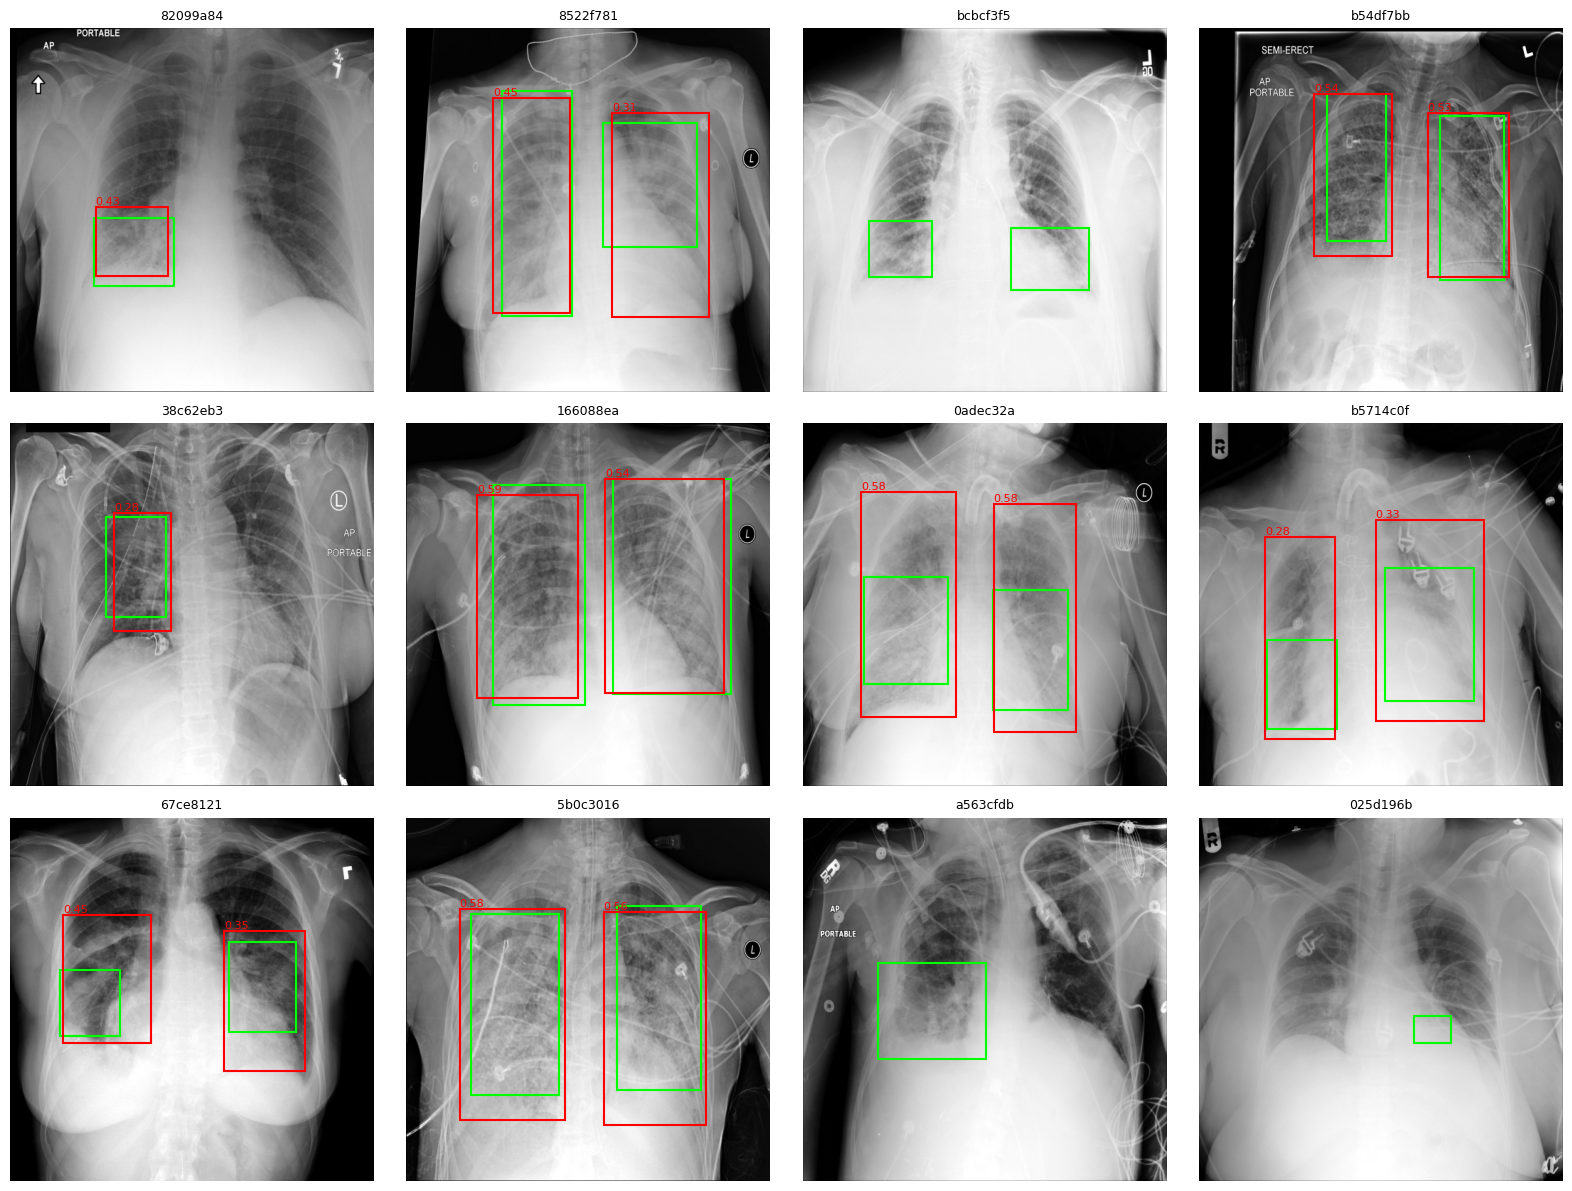

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ultralytics import YOLO
model = YOLO(run / "weights" / "best.pt")

def show_preds(img_dir, lab_dir, n=12, seed=0, conf=0.25, cols=4):
    paths = sorted(img_dir.glob("*.png"))
    random.Random(seed).shuffle(paths)
    paths = paths[:n]
    results = model.predict([str(p) for p in paths], imgsz=SIZE, conf=conf, verbose=False)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    for ax, p, r in zip(axes.flat, paths, results):
        ax.imshow(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), cmap="gray")
        for line in (lab_dir / f"{p.stem}.txt").read_text().splitlines():      # настоящие
            _, cx, cy, w, h = map(float, line.split())
            ax.add_patch(patches.Rectangle(((cx - w / 2) * SIZE, (cy - h / 2) * SIZE),
                         w * SIZE, h * SIZE, fill=False, edgecolor="lime", linewidth=1.5))
        for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):  # предсказанные
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                         fill=False, edgecolor="red", linewidth=1.5))
            ax.text(x1, y1 - 3, f"{c:.2f}", color="red", fontsize=8)
        ax.set_title(p.stem[:8], fontsize=9)
        ax.axis("off")
    for ax in axes.flat[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_preds(root / "val" / "images", root / "val" / "labels")

## 5. YOLO на test

Состав такой же, как у val (все больные + 25% фона), поэтому цифры сравнимы с последней строкой обучения.

In [ ]:
# --- состав test: все больные + 25% фона, как в val ---
run = Path(results.save_dir)
full = pd.read_csv(project / "meta.csv")
test_meta = full[full["split"] == "test"]
sick_t = test_meta[test_meta["label"] == 2]
bg_t = test_meta[test_meta["label"] != 2].sample(int(len(sick_t) * 0.25), random_state=SEED)
test_yolo = pd.concat([sick_t, bg_t])

(root / "test" / "images").mkdir(parents=True, exist_ok=True)
(root / "test" / "labels").mkdir(parents=True, exist_ok=True)

# --- PNG и .txt, тот же цикл, что для train/val ---
for pid in tqdm(test_yolo["patientId"]):
    img, _ = resize_img(read_dicom(train_image_path / f"{pid}.dcm"), SIZE)
    cv2.imwrite(str(root / "test" / "images" / f"{pid}.png"), img)

    lines = []
    for b in boxes[boxes["patientId"] == pid].itertuples():
        cx = (b.x + b.width / 2) / SIZE
        cy = (b.y + b.height / 2) / SIZE
        lines.append(f"0 {cx:.6f} {cy:.6f} {b.width / SIZE:.6f} {b.height / SIZE:.6f}")
    (root / "test" / "labels" / f"{pid}.txt").write_text("\n".join(lines))

# --- отдельный yaml, где указан test ---
(root / "data_test.yaml").write_text(
    "path: /content/dataset\ntrain: train/images\nval: val/images\ntest: test/images\n"
    "nc: 1\nnames: ['opacity']\n")

# --- проверка лучшей модели на test ---
model = YOLO(run / "weights" / "best.pt")
metrics = model.val(data=str(root / "data_test.yaml"), split="test", imgsz=SIZE, batch=32,
                    project=str(project / "yolo"), name="test_eval")

print(f"precision: {metrics.box.mp:.4f}")
print(f"recall:    {metrics.box.mr:.4f}")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")

100%|██████████| 1503/1503 [00:42<00:00, 35.37it/s]


Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO26m summary (fused): 130 layers, 20,350,223 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2227.7±815.7 MB/s, size: 116.4 KB)
val: Scanning /content/dataset/test/labels... 1503 images, 300 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1503/1503 881.5it/s 1.7s
val: New cache created: /content/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 5.1it/s 9.2s
                   all       1503       1886      0.496       0.58      0.521      0.195
Speed: 0.6ms preprocess, 1.9ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/MyDrive/rsna_project_final/yolo/test_eval
precision: 0.4956
recall:    0.5795
mAP50:     0.5212
mAP50-95:  0.1955


## 6. Метрика соревнования

Для каждого снимка при порогах IoU 0.40, 0.45 … 0.75 считается `TP / (TP + FP + FN)`, затем среднее по порогам и по снимкам.
- нет разметки и нет предсказаний -> снимок не учитывается;
- нет разметки, но есть хоть один бокс -> снимок получает 0.

Поэтому каждый лишний бокс на здоровом снимке дорог и классификатор перед YOLO отсекает такие снимки.

In [ ]:
THRESHOLDS = np.round(np.arange(0.4, 0.76, 0.05), 2)   # 0.4, 0.45, ..., 0.75

def iou_matrix(a, b):
    """IoU каждого бокса из a с каждым из b. Боксы — (n, 4): x, y, width, height."""
    ax1, ay1, ax2, ay2 = a[:, 0], a[:, 1], a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx1, by1, bx2, by2 = b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2) - np.maximum(ax1[:, None], bx1), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2) - np.maximum(ay1[:, None], by1), 0, None)
    inter = iw * ih
    union = (a[:, 2] * a[:, 3])[:, None] + b[:, 2] * b[:, 3] - inter
    return inter / union


def image_ap(gt, pred, scores):
    """AP одного снимка по правилам Kaggle. None — снимок не учитывается."""
    if len(gt) == 0 and len(pred) == 0:
        return None
    if len(gt) == 0 or len(pred) == 0:
        return 0.0
    pred = pred[np.argsort(-scores)] # сначала самые уверенные
    ious = iou_matrix(pred, gt) # (число предсказаний, число настоящих)
    aps = []
    for t in THRESHOLDS:
        matched, tp = set(), 0
        for i in range(len(pred)):
            cand = [j for j in range(len(gt)) if j not in matched and ious[i, j] > t]
            if cand: # совпал с ещё не занятым настоящим боксом
                matched.add(max(cand, key=lambda j: ious[i, j]))
                tp += 1
        fp, fn = len(pred) - tp, len(gt) - tp
        aps.append(tp / (tp + fp + fn))
    return float(np.mean(aps))

## 7. Подбор порогов цепочки

YOLO один раз проходит по всем снимкам val и test (порог 0.01), дальше перебираются пары `t2 × conf` без повторных прогонов. Пороги выбираются на val, на test проверяются один раз. `t2 = 0` вариант «только YOLO».

In [ ]:
# --- данные: вероятности классификатора и настоящие боксы ---
val = pd.read_csv(project / "classifier" / "val_probs.csv")
test = pd.read_csv(project / "classifier" / "test_probs_f1.csv")
gt_boxes = {pid: g[["x", "y", "width", "height"]].to_numpy() for pid, g in boxes.groupby("patientId")}

# --- YOLO на каждом снимке один раз ---
def yolo_all(ids):
    out = {}
    for pid in tqdm(ids):
        img, _ = resize_img(read_dicom(train_image_path / f"{pid}.dcm"), SIZE)
        r = model.predict(np.repeat(img[..., None], 3, axis=2), imgsz=SIZE, conf=0.01, verbose=False)[0]
        xyxy = r.boxes.xyxy.cpu().numpy()
        out[pid] = (np.c_[xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]], r.boxes.conf.cpu().numpy())
    return out

val_yolo = yolo_all(val["patientId"])
test_yolo = yolo_all(test["patientId"])

# --- метрика цепочки при двух порогах ---
def chain_score(df, yolo, t2, conf):
    aps = []
    for pid, p2 in zip(df["patientId"], df["prob2"]):
        pred, scores = yolo[pid]
        keep = (scores >= conf) & (p2 >= t2) # гейт классификатора + порог YOLO
        ap = image_ap(gt_boxes.get(pid, np.zeros((0, 4))), pred[keep], scores[keep])
        if ap is not None:
            aps.append(ap)
    return np.mean(aps)

# --- перебор на val, проверка на test ---
best = max((chain_score(val, val_yolo, t2, c), t2, c)
           for t2 in np.arange(0, 0.81, 0.05) for c in np.arange(0.05, 0.81, 0.05))
score_val, t2, conf = best
print(f"лучшие пороги: prob2 >= {t2:.2f}, conf >= {conf:.2f} | val {score_val:.4f}")
print(f"test: {chain_score(test, test_yolo, t2, conf):.4f}")

100%|██████████| 5337/5337 [03:32<00:00, 25.16it/s]


лучшие пороги: prob2 >= 0.50, conf >= 0.25 | val 0.2206
test: 0.2050


## 8. Загрузка моделей и отправка на Kaggle

Цепочка на 3 000 снимках закрытого теста. Боксы возвращаются из 512 в исходные 1024 и пишутся в `submission.csv`.

In [ ]:
import timm, torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
cls = timm.create_model("convnextv2_tiny.fcmae_ft_in22k_in1k", pretrained=False, num_classes=3, in_chans=1)
cls.load_state_dict(torch.load(project / "classifier" / "classifier_best_for_f1.pt", map_location=DEVICE))
cls = cls.to(DEVICE).eval()
yolo = YOLO(run / "weights" / "best.pt")

rows = []
for path in tqdm(sorted((extract_dir / "stage_2_test_images").glob("*.dcm"))):
    img, scale = resize_img(read_dicom(path), SIZE)

    x = torch.from_numpy(img).float().div(255)[None, None]
    with torch.no_grad():
        p2 = torch.softmax(cls(((x - 0.449) / 0.226).to(DEVICE)), dim=1)[0, 2].item()

    pred = ""
    if p2 >= t2: # гейт классификатора
        r = yolo.predict(np.repeat(img[..., None], 3, axis=2), imgsz=SIZE, conf=conf, verbose=False)[0]
        for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy() / scale, r.boxes.conf.cpu().numpy()):
            pred += f"{c:.3f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f} "
    rows.append(dict(patientId=path.stem, PredictionString=pred.strip()))

sub = pd.DataFrame(rows)
sub.to_csv(project / "submission.csv", index=False)
print("снимков с боксами:", (sub["PredictionString"] != "").sum(), "из", len(sub))

100%|██████████| 3000/3000 [02:23<00:00, 20.98it/s]

снимков с боксами: 644 из 3000


## 9. Заключительный тест цепочки от DICOM

Обе модели работают прямо от снимка, без сохранённых вероятностей. Число должно совпасть с результатом на test из шага 7.

In [ ]:
test_ids = full.loc[full["split"] == "test", "patientId"]

aps = []
for pid in tqdm(test_ids):
    img, _ = resize_img(read_dicom(train_image_path / f"{pid}.dcm"), SIZE)

    x = torch.from_numpy(img).float().div(255)[None, None]
    with torch.no_grad():
        p2 = torch.softmax(cls(((x - 0.449) / 0.226).to(DEVICE)), dim=1)[0, 2].item()

    pred, scores = np.zeros((0, 4)), np.zeros(0)
    if p2 >= t2:
        r = yolo.predict(np.repeat(img[..., None], 3, axis=2), imgsz=SIZE, conf=conf, verbose=False)[0]
        xyxy = r.boxes.xyxy.cpu().numpy()
        pred, scores = np.c_[xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]], r.boxes.conf.cpu().numpy()

    ap = image_ap(gt_boxes.get(pid, np.zeros((0, 4))), pred, scores)
    if ap is not None:
        aps.append(ap)

print(f"test: метрика цепочки {np.mean(aps):.4f}")

100%|██████████| 5337/5337 [04:12<00:00, 21.17it/s]

test: метрика цепочки 0.2047


## Итог

- На нашем test цепочка даёт **0.205** по метрике соревнования, на закрытом тесте Kaggle - **0.121** (Private).
- Доля снимков с боксами на тесте Kaggle близка к нашей валидации, так что пайплайн работает одинаково; разница, скорее всего, в самих тестовых данных и в подходе (боксы, размеченные иначе, чем train).
- Главный резерв качества детектор: он находит примерно половину очагов.